In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/medical_insurance_20000.csv")

In [4]:
df.head()

,Age,Sex,BMI,Children,Smoker,Region,InsuranceCharges
0,22,male,19.05,5,no,southwest,15637.99
1,54,female,27.63,1,yes,southwest,43426.14
2,48,male,19.51,2,no,northeast,20202.72
3,38,female,42.25,1,no,southeast,26100.53
4,38,female,31.27,2,no,northeast,20871.58


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               20000 non-null  int64  
 1   Sex               20000 non-null  object 
 2   BMI               20000 non-null  float64
 3   Children          20000 non-null  int64  
 4   Smoker            20000 non-null  object 
 5   Region            20000 non-null  object 
 6   InsuranceCharges  20000 non-null  float64
dtypes: float64(2), int64(2), object(3)
memory usage: 1.1+ MB


In [6]:
df.describe()

,Age,BMI,Children,InsuranceCharges
count,20000.000000,20000.000000,20000.000000,20000.000000
mean,40.837550,30.070797,2.503000,25128.458907
std,13.540632,6.000468,1.708343,8371.480966
min,18.000000,15.000000,0.000000,5955.790000
25%,29.000000,26.000000,1.000000,19225.002500
50%,41.000000,30.040000,3.000000,23224.960000
75%,53.000000,34.100000,4.000000,28326.780000
max,64.000000,53.000000,5.000000,55622.590000


In [7]:
df.isnull().sum()

Age                 0
Sex                 0
BMI                 0
Children            0
Smoker              0
Region              0
InsuranceCharges    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

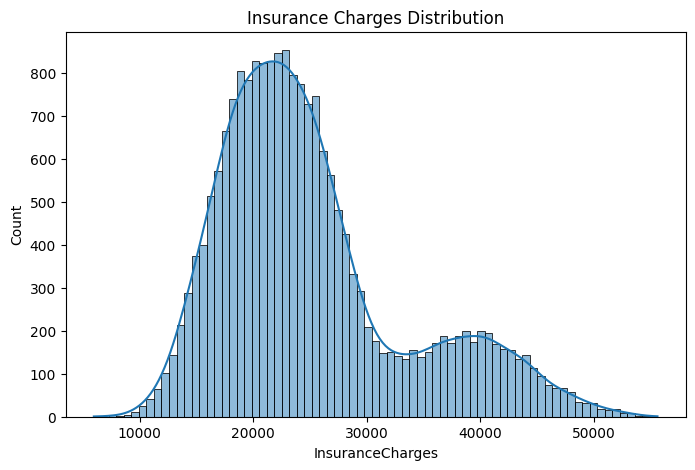

In [9]:
plt.figure(figsize=(8,5))
sns.histplot(df["InsuranceCharges"], kde=True)
plt.title("Insurance Charges Distribution")
plt.show()

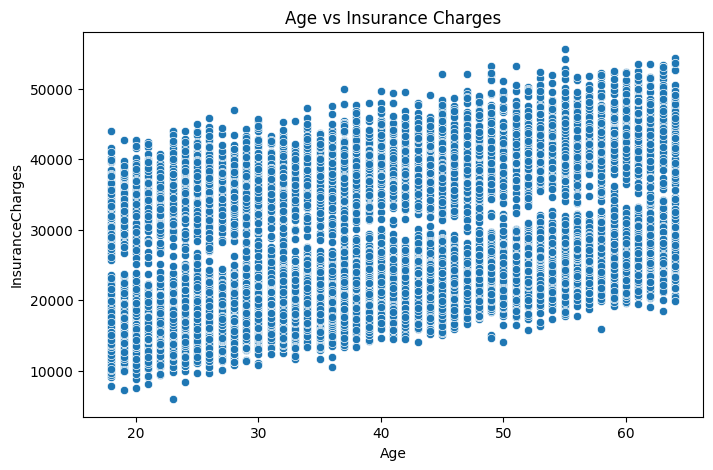

In [10]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="Age", y="InsuranceCharges")
plt.title("Age vs Insurance Charges")
plt.show()

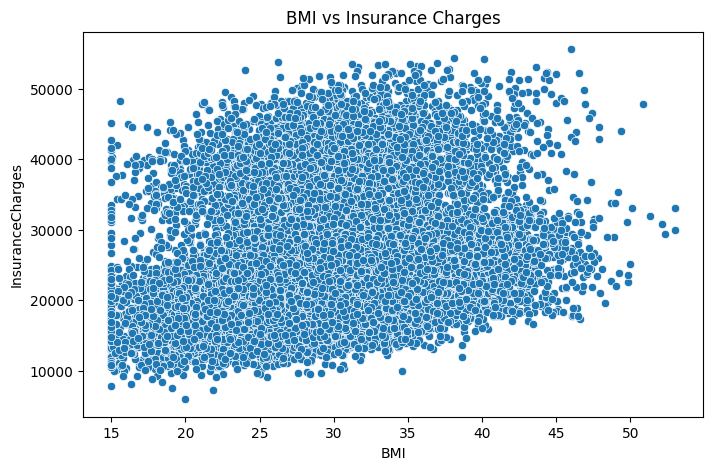

In [11]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="BMI", y="InsuranceCharges")
plt.title("BMI vs Insurance Charges")
plt.show()

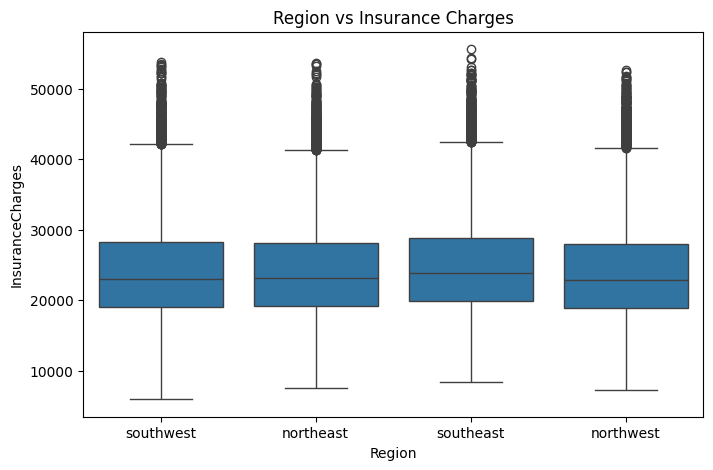

In [12]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Region", y="InsuranceCharges")
plt.title("Region vs Insurance Charges")
plt.show()

In [13]:
X = df.drop("InsuranceCharges", axis=1)
y = df["InsuranceCharges"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (20000, 6)
y Shape: (20000,)


In [14]:
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = X.select_dtypes(include=["object"]).columns

print("Numerical Columns:", list(numerical_cols))
print("Categorical Columns:", list(categorical_cols))

Numerical Columns: ['Age', 'BMI', 'Children']
Categorical Columns: ['Sex', 'Smoker', 'Region']


In [15]:
from sklearn.model_selection import train_test_split,RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (16000, 6)
Testing Data: (4000, 6)


In [17]:
preprocessor = ColumnTransformer(transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)])

In [19]:
rf_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1))])
rf_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Age','Sex','BMI','Children','Smoker','Region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with

In [20]:
y_pred = rf_model.predict(X_test)
print("Actual Values:", y_test[:10].values)
print("Predicted Values:", y_pred[:10])

Actual Values: [20646.44 28062.97 16978.44 16176.27 46573.52 18010.63 19500.35 44323.14
 23963.27 23336.05]
Predicted Values: [21916.6743 26678.8571 17314.4214 16815.9196 44546.3072 18727.9153
 19900.8222 40830.3639 24625.9439 26238.1784]


# Regression Evaluation Metrics

In [27]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [28]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 1913.9644325502973
MSE: 6229904.656261454
RMSE: 2495.977695465537
R2 Score: 0.9112874626514051


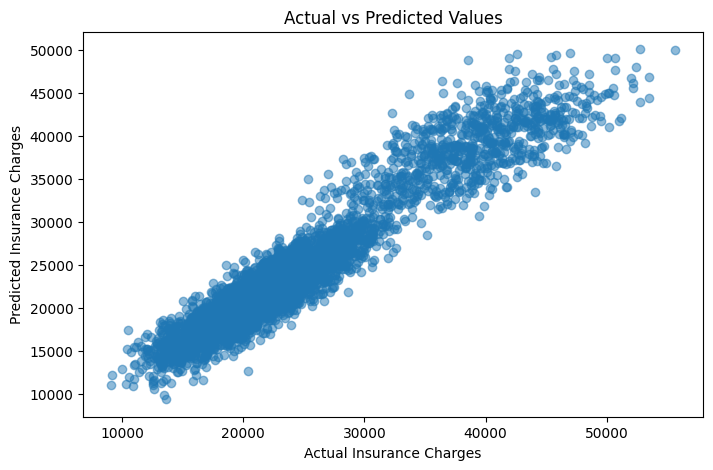

In [29]:
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual Insurance Charges")
plt.ylabel("Predicted Insurance Charges")
plt.title("Actual vs Predicted Values")
plt.show()

In [30]:
param_grid = {
    "regressor__n_estimators": [100, 150, 200, 300],
    "regressor__max_depth": [None, 10, 20, 30],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [1, 2, 4],
    "regressor__max_features": [1.0, "sqrt"]}

In [31]:
random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=1)
random_search.fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'regressor__max_depth': [None, 10, ...], 'regressor__max_features': [1.0, 'sqrt'], 'regressor__min_samples_leaf': [1, 2, ...], 'regressor__min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``

In [32]:
print("Best Parameters:")
print(random_search.best_params_)
print("\nBest CV R2 Score:")
print(random_search.best_score_)

Best Parameters:
{'regressor__n_estimators': 150, 'regressor__min_samples_split': 5, 'regressor__min_samples_leaf': 1, 'regressor__max_features': 1.0, 'regressor__max_depth': 10}

Best CV R2 Score:
0.918643899322399


In [33]:
best_model = random_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)
print("Tuned MAE:", mean_absolute_error(y_test, y_pred_tuned))
print("Tuned RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_tuned)))
print("Tuned R2 Score:", r2_score(y_test, y_pred_tuned))

Tuned MAE: 1833.5849412185369
Tuned RMSE: 2389.0441999758673
Tuned R2 Score: 0.9187259371594135


In [34]:
feature_names = (
    best_model.named_steps["preprocessing"]
    .get_feature_names_out())

importance = (
    best_model.named_steps["regressor"]
    .feature_importances_
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

feature_importance.head(10)

,Feature,Importance
6,cat__Smoker_yes,0.677251
0,num__Age,0.192148
1,num__BMI,0.063715
5,cat__Smoker_no,0.048382
2,num__Children,0.012968
9,cat__Region_southeast,0.001687
10,cat__Region_southwest,0.000940
8,cat__Region_northwest,0.000883
7,cat__Region_northeast,0.000802
4,cat__Sex_male,0.000619


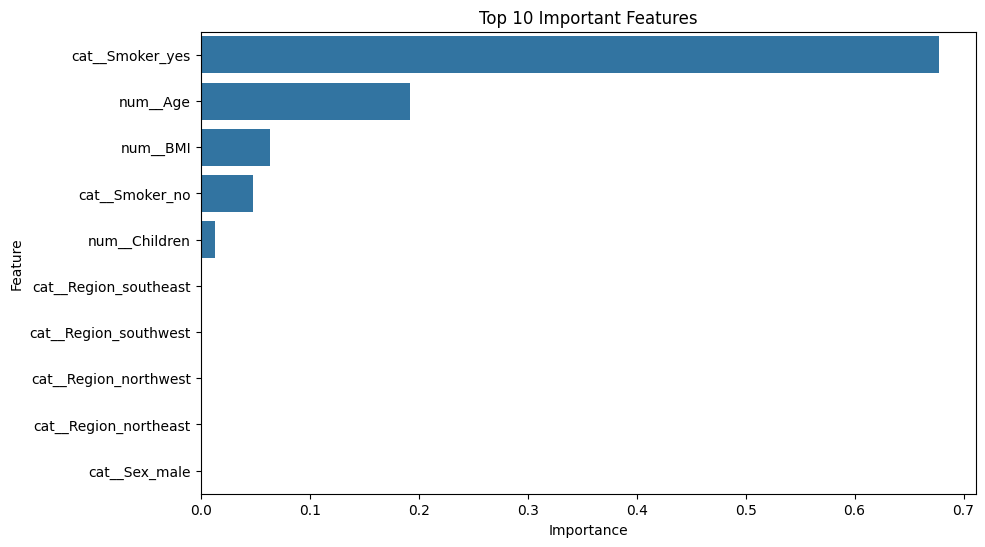

In [35]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")
plt.show()

In [36]:
new_customer = pd.DataFrame([{
    "Age": 35,
    "Sex": "male",
    "BMI": 28.5,
    "Children": 2,
    "Smoker": "no",
    "Region": "southwest"}])

prediction = best_model.predict(new_customer)
print("Predicted Insurance Charges:", round(prediction[0], 2))

Predicted Insurance Charges: 19159.05


In [38]:
import joblib
joblib.dump(best_model, "medical_insurance_model.pkl")
print("Model Saved Successfully!")

Model Saved Successfully!


In [39]:
loaded_model = joblib.load("medical_insurance_model.pkl")
result = loaded_model.predict(new_customer)
print("Predicted Insurance Charges:", round(result[0], 2))

Predicted Insurance Charges: 19159.05
